# Identification des paramètres thermiques par CNN-GRU

## Objectif de l'expérience

Cette expérience étudie une architecture hybride combinant un **réseau de neurones convolutif unidimensionnel (CNN 1D)** et une **unité récurrente à portes (GRU)** pour estimer les propriétés thermiques d'un bâtiment à partir des séries temporelles de température intérieure $T(t)$ et de sollicitation thermique $U(t)$.

Le CNN 1D permet d'extraire des motifs locaux dans les signaux, notamment les variations de température associées aux sollicitations thermiques. Le GRU exploite ensuite ces représentations pour apprendre les dépendances temporelles et les effets de l'inertie thermique.



## 1. Environnement d'exécution

Les fonctions de chargement des données, de définition des modèles, d'entraînement et d'évaluation sont organisées dans le module `src/coenergy/`, afin de faciliter la réutilisation du code et la reproductibilité des expériences.

In [18]:

from pathlib import Path
import sys
import shutil

import torch
from IPython.display import display


def find_source_directory():
    """Localise le dossier contenant les modules du projet."""

    # Recherche sur le PC
    current_directory = Path.cwd()

    for directory in [current_directory, *current_directory.parents]:
        source_directory = directory / "src"

        if (source_directory / "coenergy" / "loss.py").is_file():
            return source_directory

    # Recherche sur Kaggle
    kaggle_directory = Path("/kaggle/input")

    if kaggle_directory.exists():
        for file in kaggle_directory.rglob("loss.py"):
            if file.parent.name == "coenergy":
                return file.parent.parent

    raise FileNotFoundError("Modules coEnergy introuvables.")


source_directory = find_source_directory()
sys.path.insert(0, str(source_directory))

from coenergy.data import load_data, BatchStore
from coenergy.models import build_model
from coenergy.loss import reconstruct_six, family_loss
from coenergy.training import default_config, seed_everything, Experiment
from coenergy.evaluation import evaluate_all, extreme_diagnostics
from coenergy.plotting import plot_training, plot_scores, plot_scatter

print("Modules coEnergy chargés avec succès.")
print("Chemin :", source_directory)
print("GPU disponible :", torch.cuda.is_available())


Modules coEnergy chargés avec succès.
Chemin : /kaggle/input/datasets/bilalaouiss/dataset/coenergy_modules_kaggle/src
GPU disponible : True


## 2. Configuration expérimentale

L'entraînement du CNN-GRU repose sur **100 époques**, des mini-batchs de **1 024 simulations** et l'optimiseur **AdamW**, avec un ajustement du taux d'apprentissage selon la perte de validation.

Les hyperparamètres sont définis dans `training.py` et conservés identiques pour les modèles de référence afin de garantir une comparaison cohérente.

Une graine aléatoire fixe et un identifiant d'expérience (`RUN_ID`) facilitent la reproductibilité et la traçabilité des entraînements.

In [19]:
MODEL_KIND = "cnn_gru"
RUN_ID = "run_001"
DATA_ROOT = (
    Path("/kaggle/input/datasets/bilalaouiss/dataset")
    if Path("/kaggle/input/datasets/bilalaouiss/dataset").is_dir()
    else None
)
RUN_TRAINING = True
RESUME = True

config = default_config(MODEL_KIND, RUN_ID)
seed_everything(config.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if Path("/kaggle/working").is_dir():
    results_directory = Path("/kaggle/working/results")
else:
    results_directory = source_directory.parent / "results"

output_directory = results_directory / MODEL_KIND / RUN_ID

print("Modèle :", MODEL_KIND)
print("Appareil :", device)
print("Époques :", config.max_epochs)
print("Taille des mini-batchs :", config.batch_size)
print("Résultats :", output_directory)

Modèle : cnn_gru
Appareil : cuda
Époques : 100
Taille des mini-batchs : 1024
Résultats : /kaggle/working/results/cnn_gru/run_001


## 3. Données préparées et partitions

Le jeu de données contient **1 000 000 de simulations**, réparties lors de l'analyse exploratoire. Les quatre partitions sont conservées pour comparer les architectures dans les mêmes conditions.

| Partition | Simulations | Utilisation |
|---|---:|---|
| Entraînement | 719 885 | Mise à jour des paramètres du réseau |
| Validation | 89 985 | Sélection du modèle et adaptation du taux d'apprentissage |
| Test principal | 89 987 | Évaluation sur des simulations non utilisées pour l'apprentissage |
| Réserve U | 100 143 | Évaluation sur des profils de sollicitation exclus des autres partitions |


In [20]:
data = load_data(DATA_ROOT, expected_n=1_000_000)

for partition_name, indices in data.splits.items():
    print(f"{partition_name:12s} : {len(indices):,} simulations")

print("Séries temporelles :", data.sequences.shape)
print("Cibles thermiques :", data.targets.shape)

Données préparées : 1,000,000 simulations
Caractéristiques MLP : 58
train        : 719,885 simulations
validation   : 89,985 simulations
test         : 89,987 simulations
reserve_u    : 100,143 simulations
Séries temporelles : (1000000, 2, 480)
Cibles thermiques : (1000000, 6)


## 4. Préparation des séries temporelles

Chaque simulation contient **480 observations** de la température $T$ et de la sollicitation $U$. L'entrée du CNN-GRU a donc la forme $(B,2,480)$, où $B$ représente le nombre de simulations du mini-batch.

Les signaux sont mis à l'échelle à partir des statistiques de la partition d'entraînement :

$$
\widetilde{T}=\frac{T-\mu_{T,\mathrm{train}}}{\sigma_{T,\mathrm{train}}},
\qquad
\widetilde{U}=\frac{U}{\mathrm{RMS}_{U,\mathrm{train}}}.
$$

La température est centrée et réduite ; la sollicitation est divisée par sa valeur quadratique moyenne, sans centrage. `BatchStore` applique les transformations enregistrées et fournit les mini-batchs au réseau.

**Le CNN-GRU n'utilise pas les caractéristiques statistiques du MLP** : il apprend directement à partir des deux séries temporelles.

In [21]:
training_data = BatchStore(
    bundle=data,
    mode="cnn_gru",
    device=device,
)

sample_signals, sample_targets = training_data.get_batch(
    data.splits["train"][:8]
)

print("Entrées du CNN-GRU :", tuple(sample_signals.shape))
print("Cibles :", tuple(sample_targets.shape))

Données cnn_gru en mémoire : cuda
Entrées du CNN-GRU : (8, 2, 480)
Cibles : (8, 6)


## 5. Architecture du CNN-GRU

Le modèle associe un **encodeur convolutif** et un **réseau récurrent GRU**. Les trois convolutions extraient des caractéristiques temporelles tout en réduisant progressivement la longueur des séquences.

| Étape | Dimensions des représentations |
|---|---|
| Entrée | $(B,2,480)$ |
| Convolution 1D : 16 canaux, noyau 7, pas 2 | $(B,16,240)$ |
| Convolution 1D : 32 canaux, noyau 5, pas 2 | $(B,32,120)$ |
| Convolution 1D : 48 canaux, noyau 5, pas 2 | $(B,48,60)$ |
| Réorganisation pour le GRU | $(B,60,48)$ |
| GRU : 64 unités cachées | $(B,60,64)$ |

Chaque convolution est suivie d'une activation **SiLU**. Le GRU produit une représentation séquentielle, dont on combine **l'état caché final** et **la moyenne des états temporels**. Cette représentation de 128 valeurs est projetée vers 64 valeurs, puis transmise à la tête de régression $64\to96\to5$, avec dropout.

Le réseau estime cinq indicateurs positifs grâce à **Softplus**, puis le coefficient total de déperdition thermique est reconstruit :

$$
\widehat{HLC}=\widehat{HLC}_{ext}+\widehat{HLC}_{mit}.
$$

L'architecture complète est définie dans `models.py` ; le nombre de paramètres entraînables est affiché ci-dessous.

In [22]:
model = build_model(MODEL_KIND, data.prep).to(device)

number_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model.eval()

with torch.no_grad():
    five_predictions = model(sample_signals)
    six_predictions = reconstruct_six(five_predictions)

print(model)
print("Paramètres entraînables :", f"{number_parameters:,}")
print("Sorties indépendantes :", tuple(five_predictions.shape))
print("Indicateurs reconstruits :", tuple(six_predictions.shape))

CNNGRUSeul(
  (cnn): Sequential(
    (0): Conv1d(2, 16, kernel_size=(7,), stride=(2,), padding=(3,))
    (1): SiLU()
    (2): Conv1d(16, 32, kernel_size=(5,), stride=(2,), padding=(2,))
    (3): SiLU()
    (4): Conv1d(32, 48, kernel_size=(5,), stride=(2,), padding=(2,))
    (5): SiLU()
  )
  (gru): GRU(48, 64, batch_first=True)
  (projection): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=96, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=96, out_features=5, bias=True)
  )
)
Paramètres entraînables : 47,429
Sorties indépendantes : (8, 5)
Indicateurs reconstruits : (8, 6)


## 6. Fonction de perte

L'apprentissage repose sur les **cinq paramètres indépendants** : $HLC_{ext}$, $HLC_{mit}$, $\tau_b$, $\tau_n$ et $\tau_\infty$. Les erreurs sont divisées par les écarts-types correspondants calculés sur le train, afin de comparer des cibles dont les échelles numériques diffèrent.

La fonction de perte regroupe les deux composantes des déperditions thermiques et les trois constantes de temps :

$$
\mathcal{L}=0{,}50\,\mathcal{L}_{HLC}+0{,}50\,\mathcal{L}_{\tau},
$$

où chaque terme correspond à la **moyenne des erreurs quadratiques normalisées** de sa famille.

Le HLC total est calculé à partir de ses composantes ; il n'est pas pénalisé une seconde fois dans la perte.

In [23]:
initial_loss = family_loss(
    five_predictions,
    sample_targets,
    data.prep["target_std"],
    hlc_weight=config.hlc_weight,
    tau_weight=config.tau_weight,
)

print("Perte initiale :", round(initial_loss.item(), 6))
print("Poids des déperditions :", config.hlc_weight)
print("Poids des constantes de temps :", config.tau_weight)

Perte initiale : 1.094374
Poids des déperditions : 0.5
Poids des constantes de temps : 0.5


## 7. Entraînement et sélection du modèle

Les paramètres du CNN-GRU sont mis à jour uniquement sur la partition `train`. À la fin de chaque époque, la fonction de perte est calculée sur `validation`, sans mise à jour des poids. Cette mesure permet d'adapter le taux d'apprentissage et de sélectionner le modèle retenu pour l'évaluation finale.

L'entraînement utilise **AdamW**, une limitation de la norme du gradient et la **précision mixte sur GPU**.

Deux checkpoints sont enregistrés : `last.pt` permet une reprise après interruption, tandis que `best.pt` contient les poids de l'époque obtenant la meilleure perte de validation. `history.csv` conserve l'évolution des pertes et du taux d'apprentissage.

Avec `RUN_TRAINING = False`, des checkpoints compatibles et l'historique doivent déjà être présents dans le dossier des résultats.

In [24]:
experiment = Experiment(
    config=config,
    bundle=data,
    store=training_data,
    model=model,
    out_dir=output_directory,
    device=device,
)

if RUN_TRAINING:
    history = experiment.fit(resume=RESUME)
    print("Époques enregistrées :", len(history))
else:
    print("Entraînement désactivé : utilisation des checkpoints existants.")

Mini-batch 100 | Loss train : 0.94844
Mini-batch 200 | Loss train : 0.93600
Mini-batch 300 | Loss train : 0.92833
Mini-batch 400 | Loss train : 0.92419
Mini-batch 500 | Loss train : 0.92075
Mini-batch 600 | Loss train : 0.91828
Mini-batch 700 | Loss train : 0.91695
Époque 001 | train=0.91691 | validation=0.93024 | meilleure=1 | durée=8.7s
Mini-batch 100 | Loss train : 0.91043
Mini-batch 200 | Loss train : 0.90716
Mini-batch 300 | Loss train : 0.90714
Mini-batch 400 | Loss train : 0.90553
Mini-batch 500 | Loss train : 0.90515
Mini-batch 600 | Loss train : 0.90488
Mini-batch 700 | Loss train : 0.90380
Époque 002 | train=0.90380 | validation=0.90929 | meilleure=2 | durée=7.9s
Mini-batch 100 | Loss train : 0.89947
Mini-batch 200 | Loss train : 0.89825
Mini-batch 300 | Loss train : 0.90028
Mini-batch 400 | Loss train : 0.90107
Mini-batch 500 | Loss train : 0.89841
Mini-batch 600 | Loss train : 0.89803
Mini-batch 700 | Loss train : 0.89783
Époque 003 | train=0.89783 | validation=0.91995 | me

## 8. Évolution de l'apprentissage

Le meilleur checkpoint est sélectionné à partir de la **perte de validation**, indépendamment des résultats obtenus sur les ensembles de test.

Les courbes des pertes d'entraînement et de validation permettent d'examiner la convergence et de repérer un éventuel surapprentissage. L'évolution du taux d'apprentissage est présentée sur un second graphique.

Meilleure époque : 100


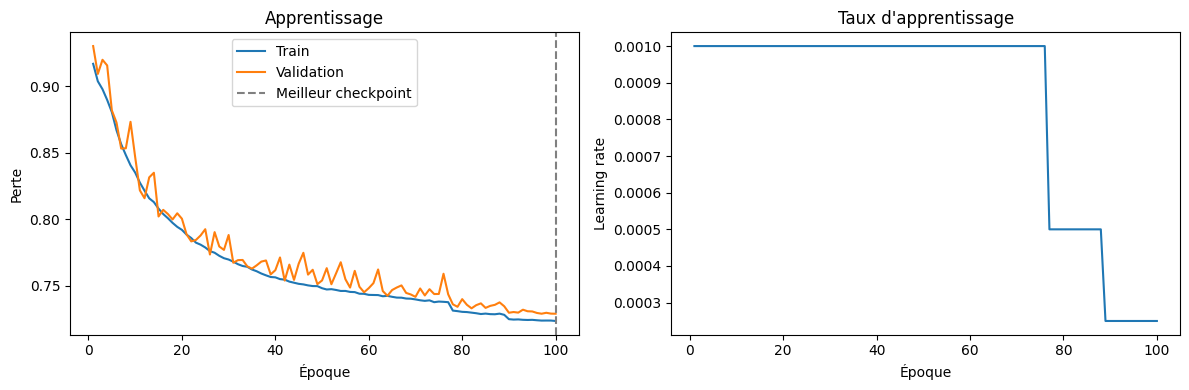

In [25]:
best_epoch = experiment.load_best()

print("Meilleure époque :", best_epoch)

plot_training(
    experiment.history_path,
    output_directory / "figures",
    best_epoch,
)

## 9. Évaluation des performances

Le modèle sélectionné est évalué sur la validation, le **test principal** et la **réserve U**. Les métriques sont calculées séparément pour les six paramètres thermiques :

- **MAE** : erreur absolue moyenne, exprimée dans l'unité du paramètre ;
- **RMSE** : racine de l'erreur quadratique moyenne, plus sensible aux grandes erreurs ;
- **$R^2$** : coefficient de détermination, comparant l'erreur du modèle à celle d'une prédiction constante égale à la moyenne réelle de la partition.

Une référence supplémentaire, fondée sur les **moyennes des cibles du train**, permet de situer les performances du CNN-GRU. Les ensembles de test sont utilisés uniquement pour l'évaluation finale.

,partition,target,unit,MAE,RMSE,R2,bias
12,test,HLC,W/K,18.7437,23.4644,0.4401,0.9100
13,test,HLCext,W/K,9.8634,12.3039,0.4815,0.5332
14,test,HLCmit,W/K,17.9740,22.3301,0.2779,0.3768
15,test,tau_b,h,7.3406,9.3509,0.1391,-0.2351
16,test,tau_n,h,1.3478,1.7159,0.2708,-0.0235
17,test,tau_inf,h,5.5388,7.0908,0.1086,-0.1351
24,reserve_u,HLC,W/K,18.7027,23.4194,0.4422,0.9076
25,reserve_u,HLCext,W/K,9.9497,12.4206,0.4713,0.6483
26,reserve_u,HLCmit,W/K,17.9368,22.2956,0.2803,0.2593
27,reserve_u,tau_b,h,7.3787,9.4277,0.1334,-0.2937


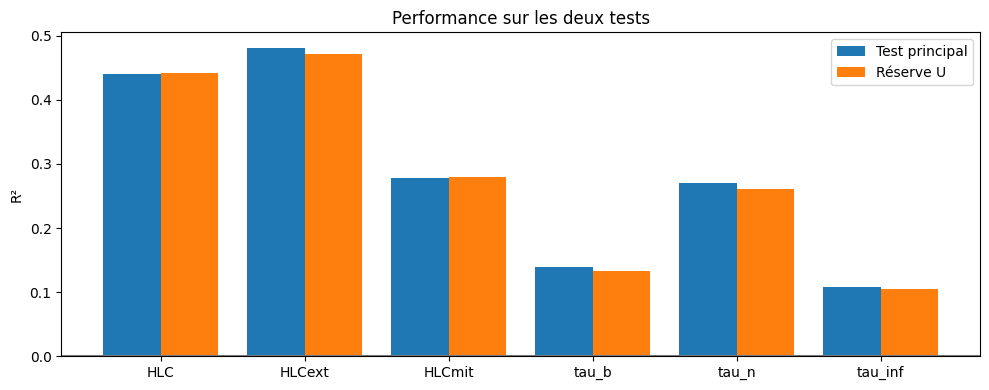

In [26]:
metrics = evaluate_all(experiment)

selected_metrics = metrics[
    (metrics["model"] == MODEL_KIND)
    & (metrics["partition"].isin(["test", "reserve_u"]))
]

display(
    selected_metrics[
        ["partition", "target", "unit", "MAE", "RMSE", "R2", "bias"]
    ].round(4)
)

plot_scores(metrics, MODEL_KIND, output_directory / "figures")

## 10. Analyse des prédictions et des valeurs extrêmes

Les diagrammes de dispersion représentent les **valeurs prédites en fonction des valeurs réelles** sur le test principal. Une bonne concordance correspond à des points proches de la diagonale.

Une analyse complémentaire porte sur les constantes de temps $\tau_b$ et $\tau_\infty$ dans les régions extrêmes de leur distribution. Les limites sont définies à partir des **5e et 95e percentiles des cibles du train**, puis les erreurs sont mesurées sur le test principal et la réserve U.

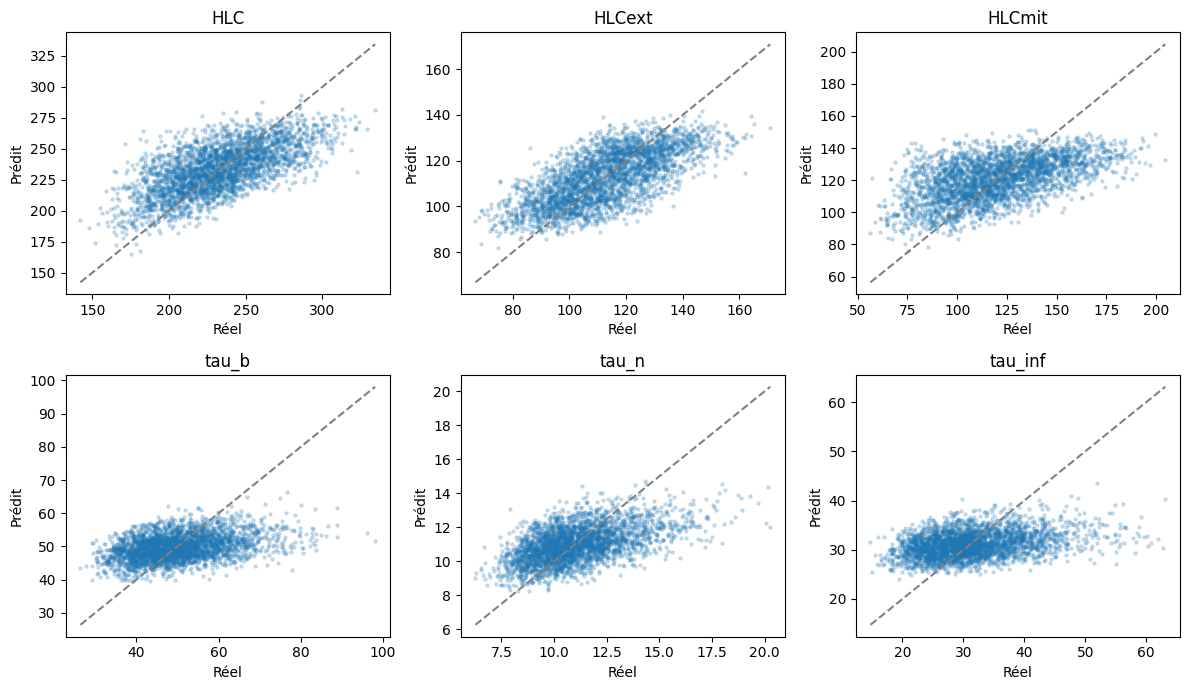

,partition,target,region,n,RMSE,bias
0,test,tau_b,5 % faibles,4447,14.000200,13.586600
1,test,tau_b,5 % élevés,4446,23.064199,-22.080299
2,test,tau_inf,5 % faibles,4475,10.439600,10.183900
3,test,tau_inf,5 % élevés,4399,18.063200,-17.284000
4,reserve_u,tau_b,5 % faibles,5055,14.109700,13.666400
5,reserve_u,tau_b,5 % élevés,5095,23.218500,-22.236000
6,reserve_u,tau_inf,5 % faibles,4987,10.495400,10.224600
7,reserve_u,tau_inf,5 % élevés,5094,18.149099,-17.385000


In [27]:
plot_scatter(
    output_directory / "predictions" / "test.npz",
    output_directory / "figures",
    seed=config.seed,
)

extreme_metrics = extreme_diagnostics(experiment)
display(extreme_metrics.round(4))

## 11. Sauvegarde des résultats

Les modèles entraînés, les configurations, les métriques d'évaluation, les prédictions et les figures sont enregistrés afin d'assurer la traçabilité et la reproductibilité des expériences.

L'ensemble des résultats est également regroupé dans une archive ZIP.

In [ ]:
results_dir = Path("/kaggle/working/results/cnn_gru/run_001")

# Vérifier que l'évaluation est terminée
if not (results_dir / "metrics.csv").exists():
    raise FileNotFoundError("Évaluation non terminée : metrics.csv absent.")

# Créer l'archive avec les résultats complets
archive = shutil.make_archive(
    "/kaggle/working/cnn_gru",
    "zip",
    root_dir=results_dir
)

file = Path(archive)

print("Fichier prêt :", file.exists())
print("Taille :", round(file.stat().st_size / 1024**2, 2), "Mo")
print("Nom :", file.name)




Fichier prêt : True
Taille : 0.7 Mo



## 12. Analyse et interprétation des résultats

L'architecture CNN-GRU associe l'extraction de motifs locaux par convolutions à la modélisation de dépendances temporelles par une unité récurrente GRU. L'objectif est d'exploiter simultanément les variations locales et l'évolution globale de la réponse thermique.

### Performances prédictives

| Paramètre | R² — Test | R² — Réserve U |
|---|---:|---:|
| HLC | 0.440 | 0.442 |
| HLCext | 0.481 | 0.471 |
| HLCmit | 0.278 | 0.280 |
| τb | 0.139 | 0.133 |
| τn | 0.271 | 0.261 |
| τ∞ | 0.109 | 0.104 |

Le CNN-GRU améliore les performances du CNN 1D sur les six indicateurs. Le gain est particulièrement important pour HLCext, dont le R² progresse de 0.233 à 0.481, et pour τb, qui passe de 0.051 à 0.139.

L'amélioration obtenue est cohérente avec l'intérêt d'une représentation tenant compte de l'évolution temporelle des signaux. Les dépendances entre les phases de sollicitation et de réponse thermique semblent apporter une information complémentaire à celle extraite par les convolutions seules.

Cependant, les constantes de temps restent difficiles à estimer. Les prédictions de τb et τ∞ présentent encore une variabilité nettement inférieure à celle des valeurs réelles, malgré l'amélioration des coefficients R².

Les résultats sur les profils U réservés sont proches de ceux du test principal, ce qui constitue un résultat encourageant pour la généralisation à de nouvelles sollicitations simulées.

### Conclusion

Parmi les architectures individuelles MLP, CNN 1D et CNN-GRU, le CNN-GRU obtient les meilleures performances sur le test principal. Il constitue ainsi une référence pertinente pour étudier l'apport d'une fusion avec les caractéristiques statistiques du MLP.
